<a href="https://colab.research.google.com/github/saran-shams/Classic_CV/blob/main/CV_LabTask01_247044.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

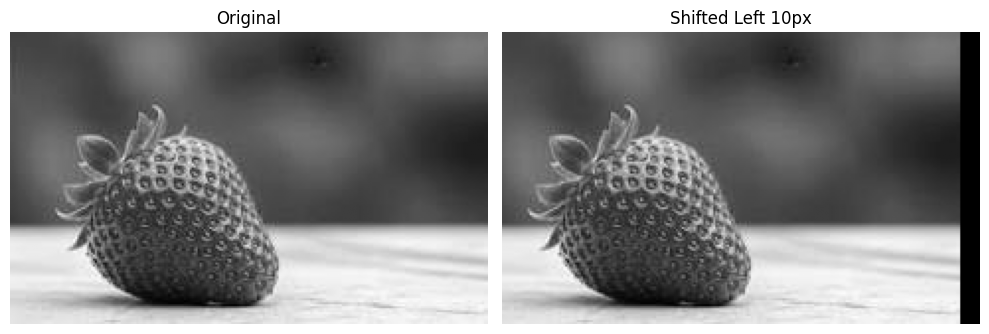

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread('/content/st.jpg', cv2.IMREAD_GRAYSCALE)
if img1 is not None:
    rows, cols = img1.shape

    M = np.float32([[1, 0, -10], [0, 1, 0]])
    shifted_img = cv2.warpAffine(img1, M, (cols, rows), borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1);
    plt.imshow(img1, cmap='gray');
    plt.title("Original");
    plt.axis('off')
    plt.subplot(1, 2, 2);
    plt.imshow(shifted_img, cmap='gray');
    plt.title("Shifted Left 10px");
    plt.axis('off')
    plt.tight_layout();
    plt.show()


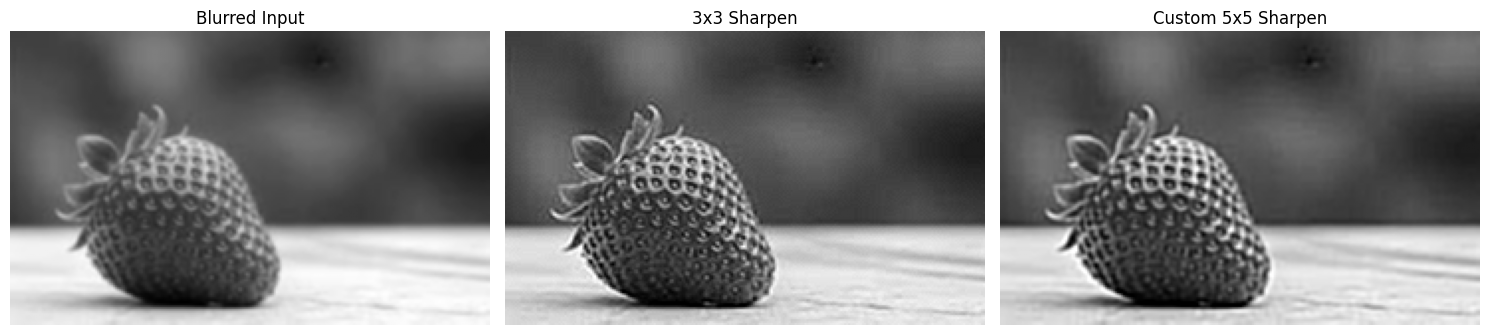

In [ ]:
img2 = cv2.imread('/content/st.jpg', cv2.IMREAD_GRAYSCALE)
if img2 is not None:
    blurred = cv2.GaussianBlur(img2, (3, 3), 0)

    k3 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
    k5 = np.array([[-1,-1,-1,-1,-1], [-1,1,2,1,-1], [-1,2,13,2,-1], [-1,1,2,1,-1], [-1,-1,-1,-1,-1]], dtype=np.float32)
    k5 /= np.sum(k5)

    out3 = cv2.filter2D(blurred, -1, k3)
    out5 = cv2.filter2D(blurred, -1, k5)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1);
    plt.imshow(blurred, cmap='gray');
    plt.title("Blurred Input");
    plt.axis('off')
    plt.subplot(1, 3, 2);
    plt.imshow(out3, cmap='gray');
    plt.title("3x3 Sharpen");
    plt.axis('off')
    plt.subplot(1, 3, 3);
    plt.imshow(out5, cmap='gray');
    plt.title("Custom 5x5 Sharpen");
    plt.axis('off')
    plt.tight_layout();
    plt.show()


# The 5x5 kernel looks sharper because it spans a wider structural area.
# However, it introduces significantly more noise and pixel grain artifacts than the 3x3 kernel.


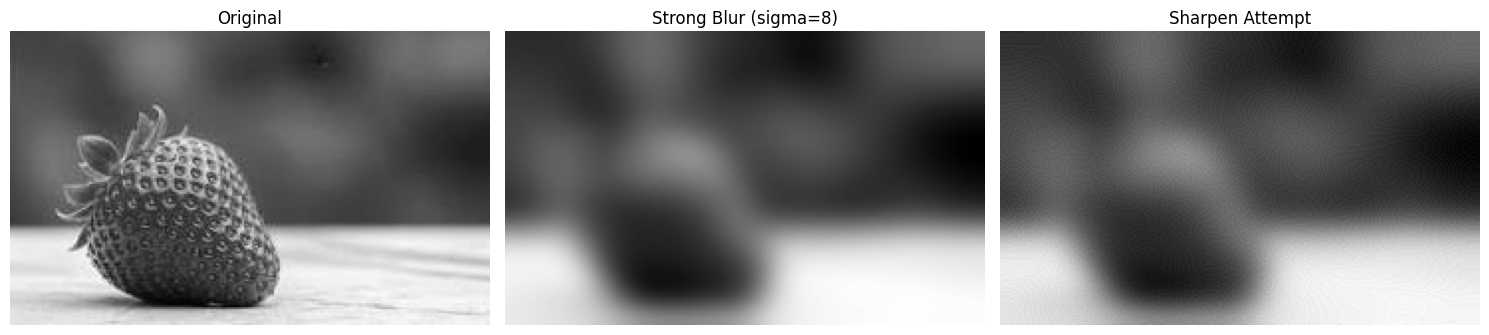

In [ ]:
img3 = cv2.imread('/content/st.jpg', cv2.IMREAD_GRAYSCALE)
if img3 is not None:
    strong_blur = cv2.GaussianBlur(img3, (0, 0), sigmaX=8, sigmaY=8)
    sharpen_k = np.array([[0, -2, 0], [-2, 9, -2], [0, -2, 0]], dtype=np.float32)
    recovered = cv2.filter2D(strong_blur, -1, sharpen_k)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1);
    plt.imshow(img3, cmap='gray');
    plt.title("Original");
    plt.axis('off')
    plt.subplot(1, 3, 2);
    plt.imshow(strong_blur, cmap='gray');
    plt.title("Strong Blur (sigma=8)");
    plt.axis('off')
    plt.subplot(1, 3, 3);
    plt.imshow(recovered, cmap='gray');
    plt.title("Sharpen Attempt");
    plt.axis('off')
    plt.tight_layout();
    plt.show()


# The fine details did not come back well. A strong Gaussian blur completely eliminates high-frequency
# data. Spatial domain filters cannot recreate missing data; they only amplify remaining low-frequency borders.


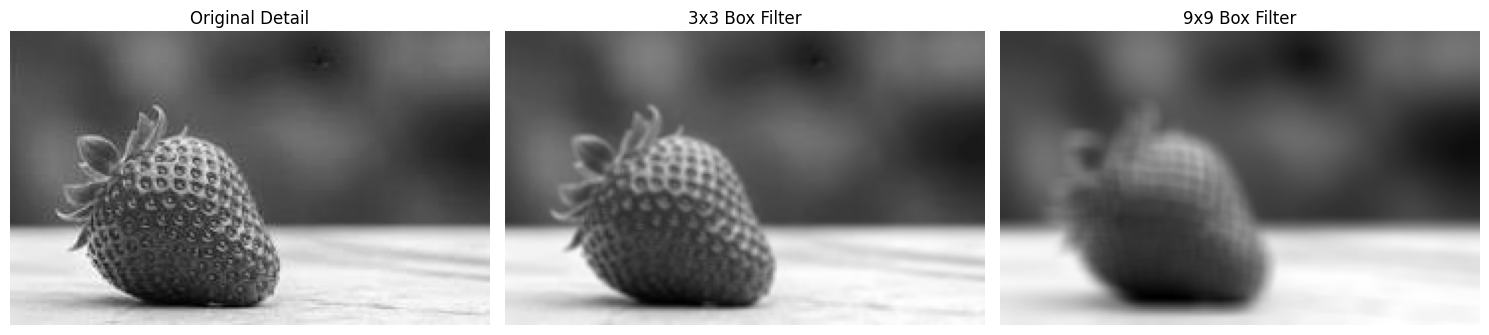

In [ ]:
img4 = cv2.imread('/content/st.jpg', cv2.IMREAD_GRAYSCALE)
if img4 is not None:
    box_3x3 = cv2.boxFilter(img4, -1, (3, 3))
    box_9 = cv2.boxFilter(img4, -1, (9, 9))

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1);
    plt.imshow(img4, cmap='gray');
    plt.title("Original Detail");
    plt.axis('off')
    plt.subplot(1, 3, 2);
    plt.imshow(box_3x3, cmap='gray');
    plt.title("3x3 Box Filter");
    plt.axis('off')
    plt.subplot(1, 3, 3);
    plt.imshow(box_9, cmap='gray');
    plt.title("9x9 Box Filter");
    plt.axis('off')
    plt.tight_layout();
    plt.show()


# The 9x9 box filter destroys significantly more detail. Larger kernels average pixels across
# a wider spatial neighborhood, wiping out high-frequency edges and heavily blurring fine textures.

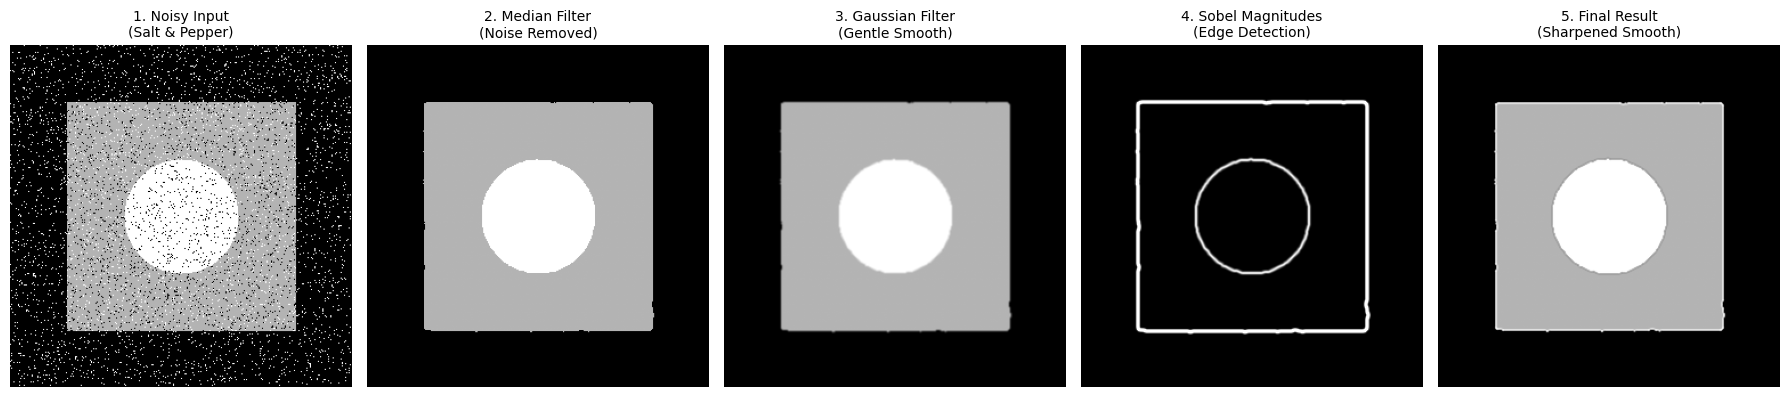

In [ ]:
def add_salt_and_pepper_noise(image, salt_prob, pepper_prob):
    """Helper function to generate a noisy test image."""
    noisy = image.copy()

    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy[tuple(coords)] = 255

    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy[tuple(coords)] = 0
    return noisy

base_img = cv2.imread('your_image.png', cv2.IMREAD_GRAYSCALE)
if base_img is None:
    base_img = np.zeros((300, 300), dtype=np.uint8)
    cv2.rectangle(base_img, (50, 50), (250, 250), 180, -1)
    cv2.circle(base_img, (150, 150), (50), 255, -1)

noisy_input = add_salt_and_pepper_noise(base_img, salt_prob=0.05, pepper_prob=0.05)


median_filtered = cv2.medianBlur(noisy_input, ksize=5)

gaussian_smoothed = cv2.GaussianBlur(median_filtered, (3, 3), 0)

sobel_x = cv2.Sobel(gaussian_smoothed, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gaussian_smoothed, cv2.CV_64F, 0, 1, ksize=3)
sobel_edges = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = np.uint8(np.clip(sobel_edges, 0, 255))

sharpen_kernel = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]], dtype=np.float32)
final_sharpened = cv2.filter2D(gaussian_smoothed, -1, sharpen_kernel)

stages = [noisy_input, median_filtered, gaussian_smoothed, sobel_edges, final_sharpened]
titles = [
    "1. Noisy Input\n(Salt & Pepper)",
    "2. Median Filter\n(Noise Removed)",
    "3. Gaussian Filter\n(Gentle Smooth)",
    "4. Sobel Magnitudes\n(Edge Detection)",
    "5. Final Result\n(Sharpened Smooth)"
]

plt.figure(figsize=(18, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(stages[i], cmap='gray')
    plt.title(titles[i], fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

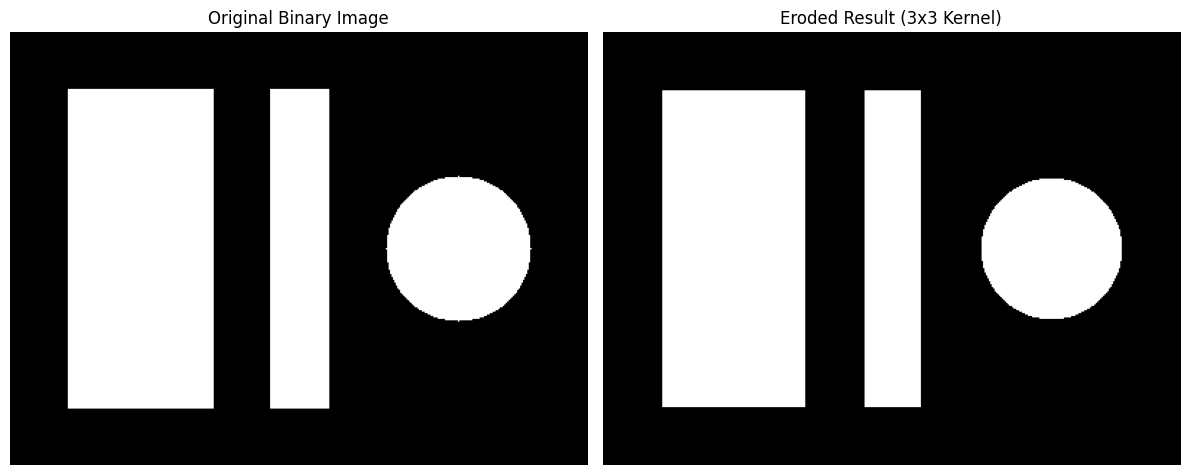

In [ ]:
img6 = cv2.imread('/content/st.jpg', cv2.IMREAD_GRAYSCALE)

if img6 is None:
    binary_img = np.zeros((300, 400), dtype=np.uint8)
    cv2.rectangle(binary_img, (40, 40), (140, 260), 255, -1)
    cv2.rectangle(binary_img, (180, 40), (220, 260), 255, -1)
    cv2.circle(binary_img, (310, 150), 50, 255, -1)
else:
    _, binary_img = cv2.threshold(img6, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel_erode = np.ones((3, 3), np.uint8)

eroded_img = cv2.erode(binary_img, kernel_erode, iterations=1)

plt.figure(figsize=(12, 6))

# Original Binary Image
plt.subplot(1, 2, 1)
plt.imshow(binary_img, cmap='gray')
plt.title("Original Binary Image", fontsize=12)
plt.axis('off')

# Eroded Image
plt.subplot(1, 2, 2)
plt.imshow(eroded_img, cmap='gray')
plt.title("Eroded Result (3x3 Kernel)", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()
